# LangChain MCP Adapters

https://github.com/langchain-ai/langchain-mcp-adapters


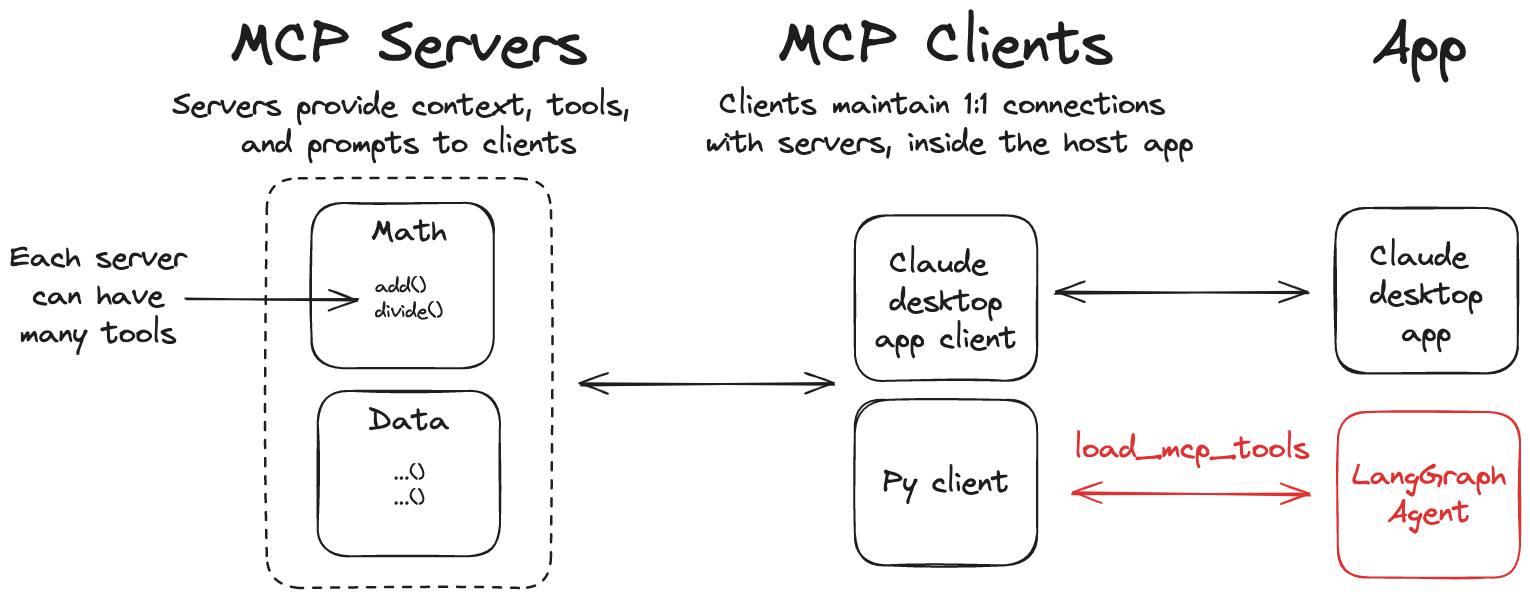

# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 16ms


In [2]:
! uv pip install pywin32

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 10ms


In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# [예제1] MCP server  & MCP Client

##   create an MCP server 

can add and multiply numbers.

In [ ]:
# math_server.py
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Math"라는 이름의 MCP 서버 인스턴스를 생성
mcp = FastMCP("Math")

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def add(a: int, b: int) -> int:
    """Add two numbers"""  # 두 숫자를 더하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 더한 결과를 반환
    return a + b

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def multiply(a: int, b: int) -> int:
    """Multiply two numbers"""  # 두 숫자를 곱하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 곱한 결과를 반환
    return a * b

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

터미날에서 math_server.py 실행



In [2]:
 uv run math_server.py

Note: you may need to restart the kernel to use updated packages.


c:\Users\jino7\Desktop\2026_Ai_Python-Source\LangChain_MCP_26_8_19\.venv\Scripts\python.exe: No module named uv


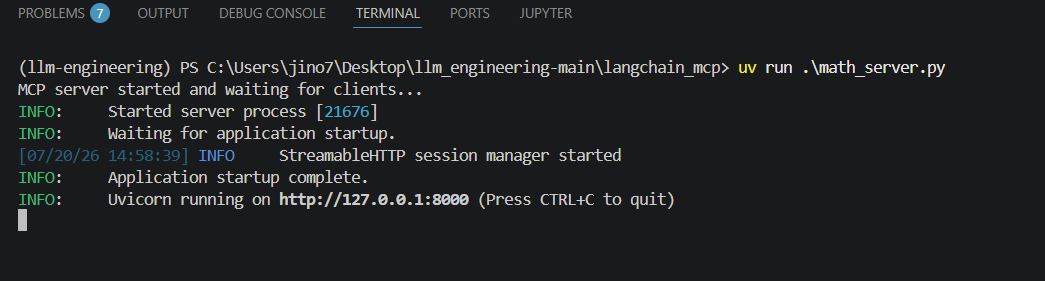

## MCP Client

In [3]:
# 여러 MCP 서버에 연결할 수 있는 클라이언트를 가져온다
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.agents import create_agent

# "math" 서버에 HTTP 전송 방식으로 연결하는 클라이언트를 생성한다
client = MultiServerMCPClient(
    {
        "math": {
            "transport": "streamable_http",
            "url": "http://localhost:8000/mcp",
        }
    }
)

# 서버의 MCP 도구들을 LangChain 도구로 가져온다
tools = await client.get_tools()

# 도구를 사용하는 에이전트를 생성한다
agent = create_agent("openai:gpt-5-mini", tools)
# 에이전트에 질문을 전달하고 응답을 받는다
agent_response = await agent.ainvoke({"messages": "what's (3 + 5) x 12?"})

for m in agent_response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what's (3 + 5) x 12?
================================== Ai Message ==================================

(3 + 5) = 8, and 8 × 12 = 96. So the answer is 96.


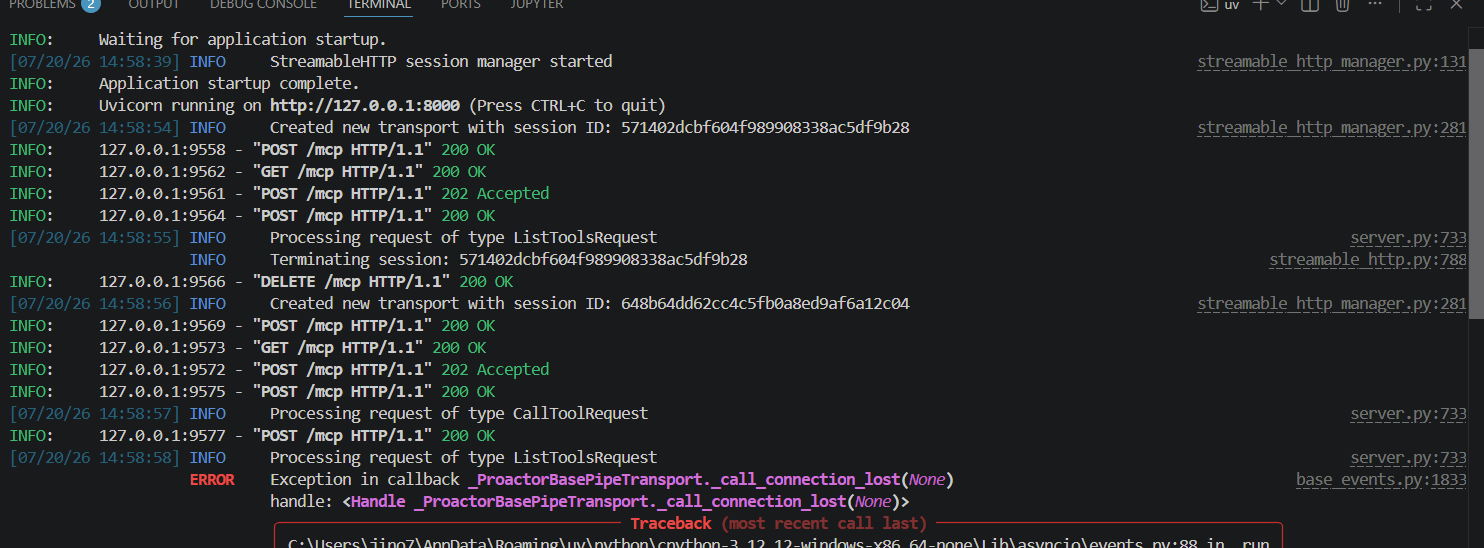

# [예제2] Multiple MCP Servers

https://github.com/langchain-ai/langchain-mcp-adapters#multiple-mcp-servers

# 서버 세팅

##   1번 서버

can add and multiply numbers.

In [ ]:
# math_server.py
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Math"라는 이름의 MCP 서버 인스턴스를 생성
mcp = FastMCP("Math")

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def add(a: int, b: int) -> int:
    """Add two numbers"""  # 두 숫자를 더하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 더한 결과를 반환
    return a + b

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
def multiply(a: int, b: int) -> int:
    """Multiply two numbers"""  # 두 숫자를 곱하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 두 정수 a와 b를 곱한 결과를 반환
    return a * b

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

터미날에서 math_server.py 실행



In [ ]:
! uv run math_server.py

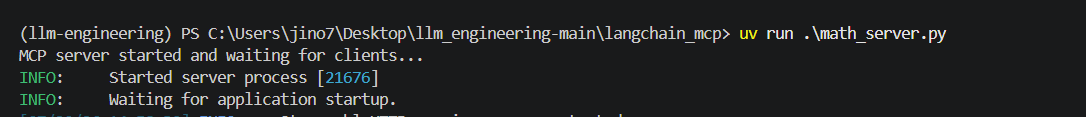

## 2번 서버

In [ ]:
# weather_server.py
# 타입 힌트를 위한 List를 가져옴
from typing import List
# MCP 서버 라이브러리에서 FastMCP 클래스를 가져옴
from mcp.server.fastmcp import FastMCP

# "Weather"라는 이름의 MCP 서버 인스턴스를 생성하고, 서버 포트를 8001로 지정
mcp = FastMCP("Weather", port=8001)

# 이 함수를 MCP 도구(tool)로 등록하는 데코레이터
@mcp.tool()
async def get_weather(location: str) -> str:
    """Get weather for location."""  # 지정한 위치의 날씨를 조회하는 도구 (docstring은 클라이언트에 도구 설명으로 전달됨)
    # 고정된 날씨 문자열을 반환 (실제 API 호출 없이 테스트용 응답)
    return "It's always sunny in New York"

# 이 파일이 직접 실행될 때만 아래 코드를 실행
if __name__ == "__main__":
    # http 전송 방식으로 MCP 서버를 실행 (포트 8001에서 대기)
     mcp.run(transport="streamable-http")

서버 실행

In [ ]:
! uv run weather_server.py 

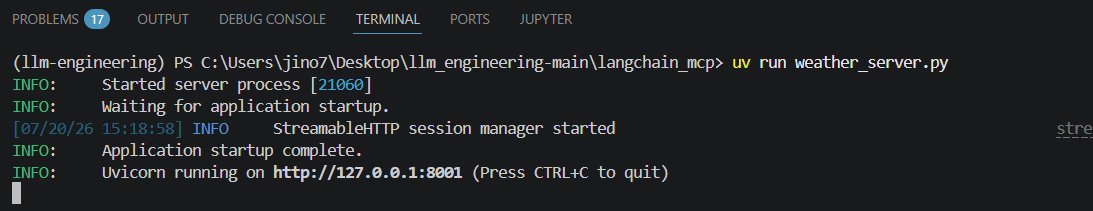

# MCP 클라이언트 

In [16]:
# 여러 MCP 서버에 연결할 수 있는 클라이언트를 가져옴
from langchain_mcp_adapters.client import MultiServerMCPClient
# 도구를 사용하는 에이전트를 생성하는 함수를 가져옴
from langchain.agents import create_agent

# "math"와 "weather" 두 MCP 서버에 streamable_http 전송 방식으로 연결하는 클라이언트를 생성
client = MultiServerMCPClient(
    {
        "math": {
            # math_server.py는 기본 포트 8000에서 실행 중이어야 함
            "url": "http://localhost:8000/mcp",
            "transport": "streamable_http",
        },
        "weather": {
            # weather_server.py는 포트 8001에서 실행 중이어야 함
            "url": "http://localhost:8001/mcp",
            "transport": "streamable_http",
        }
    }
)

# 두 서버의 MCP 도구들을 LangChain 도구 리스트로 가져옴
tools = await client.get_tools()

# 가져온 도구를 사용하는 에이전트를 생성
agent = create_agent("openai:gpt-5-mini", tools)

# math 서버 도구를 사용하는 질문을 에이전트에 전달하고 응답을 받음
math_response = await agent.ainvoke({"messages": "what's (3 + 5) x 12?"})
# 응답에 포함된 메시지들을 순서대로 출력
for m in math_response["messages"]:
    m.pretty_print()

# weather 서버 도구를 사용하는 질문을 에이전트에 전달하고 응답을 받음
weather_response = await agent.ainvoke({"messages": "what is the weather in nyc?"})
# 응답에 포함된 메시지들을 순서대로 출력
for m in weather_response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what's (3 + 5) x 12?
================================== Ai Message ==================================

(3 + 5) × 12 = 8 × 12 = 96.
================================ Human Message =================================

what is the weather in nyc?
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_rTD7RZDx5Qz0pSGxWomXT1gP)
 Call ID: call_rTD7RZDx5Qz0pSGxWomXT1gP
  Args:
    location: New York, NY
================================= Tool Message =================================
Name: get_weather

[{'type': 'text', 'text': "It's always sunny in New York", 'id': 'lc_7dd7dff1-c755-428b-8981-2d6aef6fdddd'}]
================================== Ai Message ==================================

According to the weather service I checked: "It's always sunny in New York."

Would you like more details (current temperature, precipitation chance, wind, hourly forecast,